# CliNR demo (t = 1)

A short demonstration of Clifford Noise Reduction (CliNR, arXiv:2407.06583) for the `t = 1` case.
We build a `CliNR_{1,r}` circuit for a random Clifford, confirm it is exact without noise, and show the two core effects.
The logical error rate falls with the number of checks `r`, and each random check detects a resource fault with probability `1 - 2^{-r}`.

See `clinr.py` and `estimators.py` for the implementation.
The general-`t` construction is the immediate next step; this demo covers the `t = 1` core.

In [1]:
import numpy as np
import stim
import matplotlib.pyplot as plt

import clinr
import estimators

def random_clifford(n, s, rng):
    """A random Clifford circuit of size s from {H, S, CX}."""
    C = stim.Circuit()
    for _ in range(s):
        g = rng.integers(3)
        if g == 0:   C.append("H", [int(rng.integers(n))])
        elif g == 1: C.append("S", [int(rng.integers(n))])
        else:
            a, b = rng.choice(n, 2, replace=False)
            C.append("CX", [int(a), int(b)])
    return C

n, s = 5, 100
C = random_clifford(n, s, np.random.default_rng(7))
p2 = 3e-3
p1 = p_m = p2 / 10   # two-qubit gates dominate the noise

## Noiseless correctness

With no noise, `CliNR_{1,r}` must implement `C` exactly.
Teleportation plus the Pauli correction reproduces the channel, so no Choi observable flips.

In [2]:
circ = clinr.build_clinr_1r(C, n, r=4, p1=0, p2=0, p_m=0, rng=np.random.default_rng(0))
_, obs = circ.compile_detector_sampler().sample(2000, separate_observables=True)
print("any logical observable flipped (noiseless):", bool(obs.any()))

any logical observable flipped (noiseless): False


## Logical error rate vs. number of checks

Each additional check suppresses the logical error rate.
The suppression saturates at the floor set by the unprotected teleportation gadget, so there is an optimal `r` beyond which more checks no longer help.

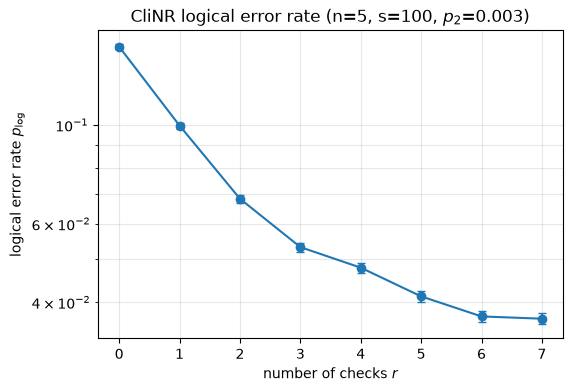

In [3]:
rs = list(range(0, 8))
pls, errs = [], []
for r in rs:
    e = estimators.p_logical(C, n, r, p1, p2, p_m, n_draws=8, shots=20_000, seed=1)
    pls.append(e.value)
    errs.append(2 * e.stderr)

plt.figure(figsize=(6, 4))
plt.errorbar(rs, pls, yerr=errs, marker="o", capsize=3)
plt.yscale("log")
plt.xlabel("number of checks $r$")
plt.ylabel("logical error rate $p_\\mathrm{log}$")
plt.title(f"CliNR logical error rate (n={n}, s={s}, $p_2$={p2})")
plt.grid(True, which="both", alpha=0.3)
plt.show()

## The detection law

Each random stabilizer check catches a resource fault with probability 1/2, so `r` independent checks detect it with probability `1 - 2^{-r}`.
This is the guarantee the scheme relies on.

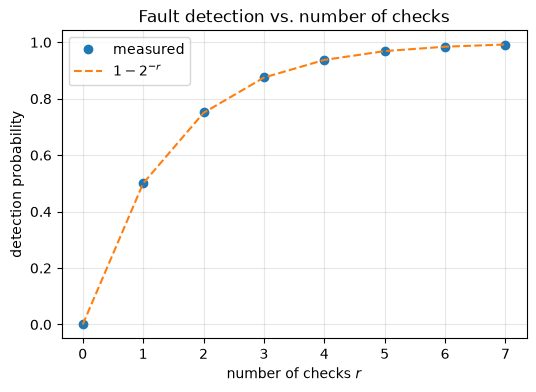

In [4]:
catch = [estimators.catch_rate(C, n, r, n_trials=30_000, seed=r).value for r in rs]

plt.figure(figsize=(6, 4))
plt.plot(rs, catch, "o", label="measured")
plt.plot(rs, [1 - 2**-r for r in rs], "--", label="$1 - 2^{-r}$")
plt.xlabel("number of checks $r$")
plt.ylabel("detection probability")
plt.title("Fault detection vs. number of checks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()